In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("NumPy version:", np.__version__)

NumPy version: 2.5.4


In [2]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1, as_frame=False)
X = mnist.data
y = mnist.target.astype(int)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)

Images shape: (70000, 784)
Labels shape: (70000,)


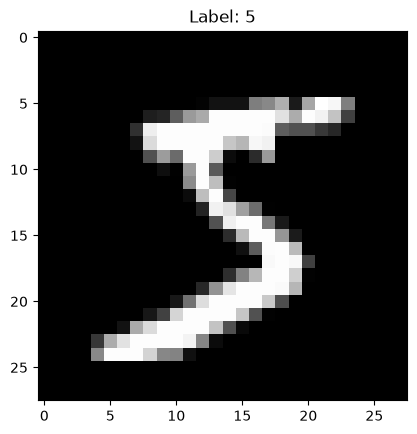

In [3]:
plt.imshow(X[0].reshape(28, 28), cmap='gray')
plt.title(f"Label: {y[0]}")
plt.show()

In [4]:
print("Smallest pixel value:", X[0].min())
print("Largest pixel value:", X[0].max())
print("First 10 labels:", y[:10])

Smallest pixel value: 0
Largest pixel value: 255
First 10 labels: [5 0 4 1 9 2 1 3 1 4]


In [5]:
X_scaled = X / 255.0
print("Min:", X_scaled.min(), "Max:", X_scaled.max())

Min: 0.0 Max: 1.0


In [6]:
X_train, X_test = X_scaled[:60000], X_scaled[60000:]
y_train, y_test = y[:60000], y[60000:]

print("Train images:", X_train.shape)
print("Test images:", X_test.shape)
print("Train labels:", y_train.shape)
print("Test labels:", y_test.shape)

Train images: (60000, 784)
Test images: (10000, 784)
Train labels: (60000,)
Test labels: (10000,)


In [7]:
print(np.bincount(y_train))

[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [8]:
def one_hot(labels, num_classes=10):
    result = np.zeros((len(labels), num_classes))
    result[np.arange(len(labels)), labels] = 1
    return result

y_train_oh = one_hot(y_train)
y_test_oh = one_hot(y_test)

print("First 3 labels:", y_train[:3])
print(y_train_oh[:3])

First 3 labels: [5 0 4]
[[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]


In [9]:
np.random.seed(42)

input_size = 784
hidden_size = 64
output_size = 10

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
b2 = np.zeros((1, output_size))

print("W1:", W1.shape, "b1:", b1.shape)
print("W2:", W2.shape, "b2:", b2.shape)

W1: (784, 64) b1: (1, 64)
W2: (64, 10) b2: (1, 10)


In [10]:
def relu(z):
    return np.maximum(0, z)

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

In [11]:
test = np.array([[1.0, 2.0, 3.0]])
print(softmax(test))
print("Sum:", softmax(test).sum())

[[0.09003057 0.24472847 0.66524096]]
Sum: 0.9999999999999999


In [12]:
def forward(X):
    z1 = X @ W1 + b1
    a1 = relu(z1)
    z2 = a1 @ W2 + b2
    a2 = softmax(z2)
    return z1, a1, z2, a2

In [13]:
z1, a1, z2, probs = forward(X_train[:5])

print("Hidden layer shape:", a1.shape)
print("Output shape:", probs.shape)
print("Each row sums to:", probs.sum(axis=1))
print("First image probabilities:")
print(np.round(probs[0], 3))
print("Network guesses:", probs.argmax(axis=1))
print("Real answers:   ", y_train[:5])

Hidden layer shape: (5, 64)
Output shape: (5, 10)
Each row sums to: [1. 1. 1. 1. 1.]
First image probabilities:
[0.053 0.228 0.056 0.085 0.051 0.084 0.103 0.103 0.06  0.178]
Network guesses: [1 1 1 0 1]
Real answers:    [5 0 4 1 9]


In [14]:
def cross_entropy(probs, y_oh):
    eps = 1e-12
    return -np.mean(np.sum(y_oh * np.log(probs + eps), axis=1))

def accuracy(probs, y_true):
    return np.mean(probs.argmax(axis=1) == y_true)

_, _, _, probs_all = forward(X_train)
print("Starting loss:", cross_entropy(probs_all, y_train_oh))
print("Starting accuracy:", accuracy(probs_all, y_train))

Starting loss: 2.419565092404081
Starting accuracy: 0.10575


In [15]:
def backward(X, y_oh, z1, a1, probs):
    m = X.shape[0]

    dz2 = (probs - y_oh) / m
    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    da1 = dz2 @ W2.T
    dz1 = da1 * (z1 > 0)
    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [16]:
Xs, ys = X_train[:20], y_train_oh[:20]
z1, a1, z2, probs = forward(Xs)
dW1, db1, dW2, db2 = backward(Xs, ys, z1, a1, probs)

print("dW1:", dW1.shape, "vs W1:", W1.shape)
print("db1:", db1.shape, "vs b1:", b1.shape)
print("dW2:", dW2.shape, "vs W2:", W2.shape)
print("db2:", db2.shape, "vs b2:", b2.shape)

dW1: (784, 64) vs W1: (784, 64)
db1: (1, 64) vs b1: (1, 64)
dW2: (64, 10) vs W2: (64, 10)
db2: (1, 10) vs b2: (1, 10)


In [17]:
def loss_on_batch():
    _, _, _, p = forward(Xs)
    return cross_entropy(p, ys)

def grad_check(param, grad, name, rows=None, n=5):
    eps = 1e-5
    rng = np.random.default_rng(0)
    for _ in range(n):
        i = rng.choice(rows) if rows is not None else rng.integers(param.shape[0])
        j = rng.integers(param.shape[1])
        old = param[i, j]
        param[i, j] = old + eps
        loss_plus = loss_on_batch()
        param[i, j] = old - eps
        loss_minus = loss_on_batch()
        param[i, j] = old
        numerical = (loss_plus - loss_minus) / (2 * eps)
        analytic = grad[i, j]
        rel_diff = abs(numerical - analytic) / max(abs(numerical) + abs(analytic), 1e-12)
        print(f"{name}[{i},{j}]  numerical={numerical:.8f}  backprop={analytic:.8f}  diff={rel_diff:.2e}")

active_pixels = np.where(Xs.sum(axis=0) > 0)[0]

grad_check(W2, dW2, "W2")
grad_check(W1, dW1, "W1", rows=active_pixels)

W2[54,6]  numerical=0.00290304  backprop=0.00290304  diff=3.70e-09
W2[32,2]  numerical=0.00149435  backprop=0.00149436  diff=7.64e-09
W2[19,0]  numerical=0.00939819  backprop=0.00939819  diff=4.18e-10
W2[4,0]  numerical=0.01444507  backprop=0.01444507  diff=2.02e-11
W2[11,8]  numerical=0.00433592  backprop=0.00433592  diff=1.38e-09
W1[621,40]  numerical=0.00283417  backprop=0.00283417  diff=3.92e-09
W1[410,17]  numerical=-0.00551035  backprop=-0.00551035  diff=1.78e-09
W1[290,2]  numerical=-0.00922057  backprop=-0.00922057  diff=1.05e-09
W1[156,1]  numerical=0.03026753  backprop=0.03026753  diff=2.62e-10
W1[213,52]  numerical=0.02976367  backprop=0.02976367  diff=4.24e-10


In [18]:
# Fresh start: re-create the weights so you can rerun this cell any time
np.random.seed(42)
W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
b2 = np.zeros((1, output_size))

learning_rate = 0.1
epochs = 10
batch_size = 128

history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

for epoch in range(epochs):
    # Shuffle so every epoch sees the batches in a different order
    order = np.random.permutation(len(X_train))
    X_shuf = X_train[order]
    y_shuf = y_train_oh[order]

    for start in range(0, len(X_train), batch_size):
        xb = X_shuf[start:start + batch_size]
        yb = y_shuf[start:start + batch_size]

        z1, a1, z2, probs = forward(xb)
        dW1, db1, dW2, db2 = backward(xb, yb, z1, a1, probs)

        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    # Measure progress after each epoch
    _, _, _, p_train = forward(X_train)
    _, _, _, p_test = forward(X_test)

    history["train_loss"].append(cross_entropy(p_train, y_train_oh))
    history["train_acc"].append(accuracy(p_train, y_train))
    history["test_loss"].append(cross_entropy(p_test, y_test_oh))
    history["test_acc"].append(accuracy(p_test, y_test))

    print(f"Epoch {epoch + 1:2d}/{epochs}  "
          f"train loss {history['train_loss'][-1]:.4f}  "
          f"train acc {history['train_acc'][-1]:.4f}  "
          f"test acc {history['test_acc'][-1]:.4f}")

Epoch  1/10  train loss 0.2970  train acc 0.9150  test acc 0.9181
Epoch  2/10  train loss 0.2349  train acc 0.9338  test acc 0.9337
Epoch  3/10  train loss 0.2005  train acc 0.9439  test acc 0.9417
Epoch  4/10  train loss 0.1757  train acc 0.9503  test acc 0.9467
Epoch  5/10  train loss 0.1574  train acc 0.9562  test acc 0.9512
Epoch  6/10  train loss 0.1417  train acc 0.9598  test acc 0.9555
Epoch  7/10  train loss 0.1282  train acc 0.9643  test acc 0.9593
Epoch  8/10  train loss 0.1178  train acc 0.9667  test acc 0.9611
Epoch  9/10  train loss 0.1093  train acc 0.9697  test acc 0.9645
Epoch 10/10  train loss 0.1017  train acc 0.9723  test acc 0.9649


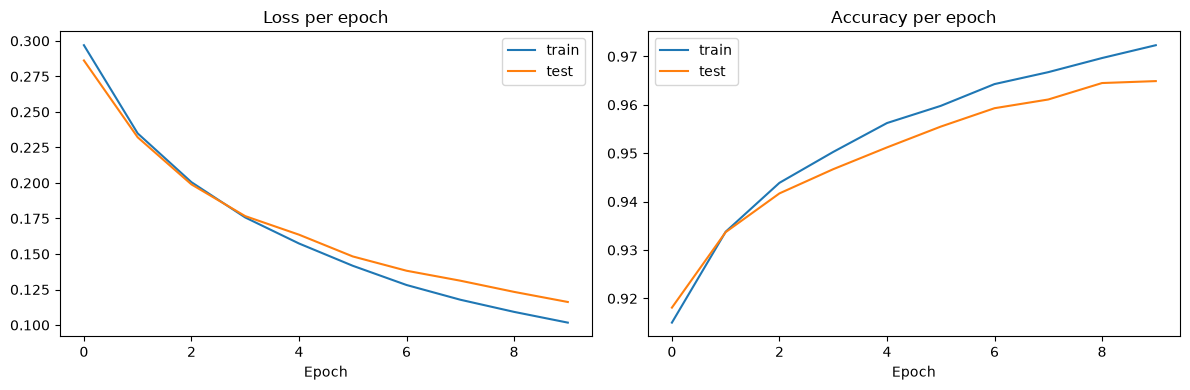

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["test_loss"], label="test")
axes[0].set_title("Loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["test_acc"], label="test")
axes[1].set_title("Accuracy per epoch")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=150)
plt.show()

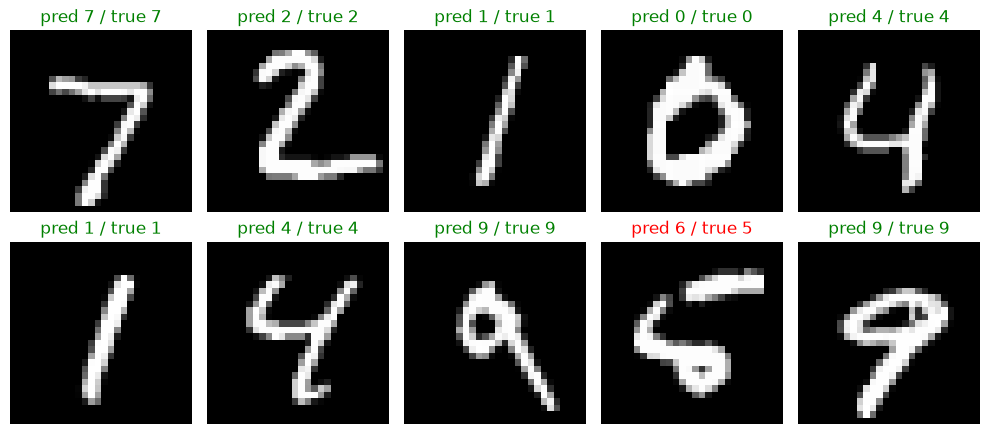

In [20]:
_, _, _, p = forward(X_test[:10])
preds = p.argmax(axis=1)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, img, pred, true in zip(axes.ravel(), X_test[:10], preds, y_test[:10]):
    ax.imshow(img.reshape(28, 28), cmap="gray")
    ax.set_title(f"pred {pred} / true {true}", color="green" if pred == true else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [21]:
print(f"Final test accuracy: {history['test_acc'][-1] * 100:.2f}%")

Final test accuracy: 96.49%


In [22]:
def init_params(hidden, seed=42):
    rng = np.random.default_rng(seed)
    return {
        "W1": rng.standard_normal((784, hidden)) * np.sqrt(2 / 784),
        "b1": np.zeros((1, hidden)),
        "W2": rng.standard_normal((hidden, 10)) * np.sqrt(2 / hidden),
        "b2": np.zeros((1, 10)),
    }

def predict(P, X):
    a1 = relu(X @ P["W1"] + P["b1"])
    return softmax(a1 @ P["W2"] + P["b2"])

def train(hidden=64, lr=0.1, epochs=5, batch_size=128, seed=42):
    P = init_params(hidden, seed)
    rng = np.random.default_rng(seed)

    for epoch in range(epochs):
        order = rng.permutation(len(X_train))
        for start in range(0, len(X_train), batch_size):
            idx = order[start:start + batch_size]
            xb, yb = X_train[idx], y_train_oh[idx]
            m = len(xb)

            z1 = xb @ P["W1"] + P["b1"]
            a1 = relu(z1)
            probs = softmax(a1 @ P["W2"] + P["b2"])

            dz2 = (probs - yb) / m
            dW2 = a1.T @ dz2
            db2 = dz2.sum(axis=0, keepdims=True)
            dz1 = (dz2 @ P["W2"].T) * (z1 > 0)
            dW1 = xb.T @ dz1
            db1 = dz1.sum(axis=0, keepdims=True)

            P["W1"] -= lr * dW1
            P["b1"] -= lr * db1
            P["W2"] -= lr * dW2
            P["b2"] -= lr * db2

    train_acc = accuracy(predict(P, X_train), y_train)
    test_acc = accuracy(predict(P, X_test), y_test)
    return train_acc, test_acc

In [23]:
results = []

tr, te = train(hidden=64, lr=0.1, epochs=5)
results.append({"experiment": "baseline", "hidden": 64, "lr": 0.1, "epochs": 5,
                "train_acc": tr, "test_acc": te})
print(f"baseline: train {tr:.4f}  test {te:.4f}")

baseline: train 0.9573  test 0.9544


In [24]:
for lr in [0.001, 0.01, 0.5, 2.0]:
    tr, te = train(hidden=64, lr=lr, epochs=5)
    results.append({"experiment": "learning rate", "hidden": 64, "lr": lr,
                    "epochs": 5, "train_acc": tr, "test_acc": te})
    print(f"lr={lr}: train {tr:.4f}  test {te:.4f}")

lr=0.001: train 0.7902  test 0.8025
lr=0.01: train 0.9021  test 0.9082
lr=0.5: train 0.9826  test 0.9732
lr=2.0: train 0.2040  test 0.2071


In [25]:
for hidden in [4, 16, 128, 256]:
    tr, te = train(hidden=hidden, lr=0.1, epochs=5)
    results.append({"experiment": "hidden size", "hidden": hidden, "lr": 0.1,
                    "epochs": 5, "train_acc": tr, "test_acc": te})
    print(f"hidden={hidden}: train {tr:.4f}  test {te:.4f}")

hidden=4: train 0.8504  test 0.8497
hidden=16: train 0.9369  test 0.9341
hidden=128: train 0.9611  test 0.9577
hidden=256: train 0.9635  test 0.9588


In [26]:
for epochs in [1, 20]:
    tr, te = train(hidden=64, lr=0.1, epochs=epochs)
    results.append({"experiment": "epochs", "hidden": 64, "lr": 0.1,
                    "epochs": epochs, "train_acc": tr, "test_acc": te})
    print(f"epochs={epochs}: train {tr:.4f}  test {te:.4f}")

epochs=1: train 0.9155  test 0.9200
epochs=20: train 0.9824  test 0.9709


In [27]:
import pandas as pd

df = pd.DataFrame(results)
df["train_acc"] = (df["train_acc"] * 100).round(2)
df["test_acc"] = (df["test_acc"] * 100).round(2)
df["gap"] = (df["train_acc"] - df["test_acc"]).round(2)
df

,experiment,hidden,lr,epochs,train_acc,test_acc,gap
0,baseline,64,0.100,5,95.73,95.44,0.29
1,learning rate,64,0.001,5,79.02,80.25,-1.23
2,learning rate,64,0.010,5,90.21,90.82,-0.61
3,learning rate,64,0.500,5,98.26,97.32,0.94
4,learning rate,64,2.000,5,20.40,20.71,-0.31
5,hidden size,4,0.100,5,85.04,84.97,0.07
6,hidden size,16,0.100,5,93.69,93.41,0.28
7,hidden size,128,0.100,5,96.11,95.77,0.34
8,hidden size,256,0.100,5,96.35,95.88,0.47
9,epochs,64,0.100,1,91.55,92.00,-0.45


In [28]:
df.to_csv("experiment_results.csv", index=False)

In [29]:
print(df.to_string(index=False))

   experiment  hidden    lr  epochs  train_acc  test_acc   gap
     baseline      64 0.100       5      95.73     95.44  0.29
learning rate      64 0.001       5      79.02     80.25 -1.23
learning rate      64 0.010       5      90.21     90.82 -0.61
learning rate      64 0.500       5      98.26     97.32  0.94
learning rate      64 2.000       5      20.40     20.71 -0.31
  hidden size       4 0.100       5      85.04     84.97  0.07
  hidden size      16 0.100       5      93.69     93.41  0.28
  hidden size     128 0.100       5      96.11     95.77  0.34
  hidden size     256 0.100       5      96.35     95.88  0.47
       epochs      64 0.100       1      91.55     92.00 -0.45
       epochs      64 0.100      20      98.24     97.09  1.15
